<a href="https://colab.research.google.com/github/NatShed/MO_Attack/blob/main/lab12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 12. Отравление данных и атаки на приватность


**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам лекции 9**

Курс «Глубокое обучение и безопасность нейронных сетей». Уровень: бакалавриат, Python и основы PyTorch.

**Вариант / seed:** _номер варианта или значение SEED_

Все эксперименты выполняются на собственных локальных моделях, открытых цифрах 8×8 и синтетических векторах.
Нет внешних API, персональных данных, ключей или скачивания весов.

## План

| Блок | Эксперимент | Главный вопрос |
|---|---|---|
| A | Baseline и label flipping | Что меняется при повреждении меток? |
| B | Backdoor и контроль известного триггера | Может ли высокая clean accuracy скрывать уязвимость? |
| C | Membership inference, shadow calibration | Насколько loss выдаёт участие в обучении? |
| D | Model inversion | Восстановлен образ класса или конкретная запись? |
| E | Model extraction | Чем fidelity отличается от accuracy? |
| F | Выводы и воспроизводимость | Какие утверждения действительно подтверждены? |


Выполняйте «Restart Kernel → Run All». CPU достаточен; время зависит от компьютера.
Не оценивайте качество работы по тому, удалось ли получить «красивую» атаку.
Корректный отрицательный результат с проверенной реализацией является полноценным результатом.

Реализуйте 6 кодовых заданий (8 функций) и аналитическое задание F1. Заглушки возвращают None: зависимые опыты честно пропускаются, а не подменяются готовыми ответами.

In [ ]:
# При необходимости выполните ОДИН РАЗ, затем перезапустите ядро:
# %pip install torch numpy scipy scikit-learn pandas matplotlib nbformat
import sys, time, copy, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
import sklearn
from sklearn.datasets import load_digits, make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, balanced_accuracy_score
from IPython.display import display

START = time.perf_counter()
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cpu"
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 10})
print({"Python": platform.python_version(), "torch": torch.__version__,
       "numpy": np.__version__, "sklearn": sklearn.__version__, "device": DEVICE})

def tensor(x):
    return torch.as_tensor(x, dtype=torch.float32)

def new_model(d, k, seed=SEED, width=64):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(d, width), nn.ReLU(),
                         nn.Linear(width, width), nn.ReLU(), nn.Linear(width, k))

def fit(x, y, k=10, epochs=140, wd=1e-4, seed=SEED, width=64, soft=False):
    model = new_model(x.shape[1], k, seed, width)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=wd)
    xt = tensor(x)
    yt = tensor(y) if soft else torch.as_tensor(y, dtype=torch.long)
    history = []
    for _ in range(epochs):
        opt.zero_grad()
        logits = model(xt)
        loss = -(yt * F.log_softmax(logits, dim=1)).sum(1).mean() if soft else F.cross_entropy(logits, yt)
        loss.backward()
        opt.step()
        history.append(loss.item())
    return model.eval(), history

def probs(model, x):
    with torch.no_grad():
        return model(tensor(x)).softmax(1).numpy()

def acc(model, x, y):
    return accuracy_score(y, probs(model, x).argmax(1))

def pending(name):
    print(f"{name}: не выполнено. Реализуйте TODO и повторите Run All.")

results = {}

{'Python': '3.13.16', 'torch': '2.11.0+cpu', 'numpy': '2.1.3', 'sklearn': '1.6.1', 'device': 'cpu'}


## A. Данные и честный контроль

Digits из scikit-learn загружается локально и не требует сети. Делим исходные индексы ДО атак:
600 train, 197 validation, 500 public query pool, 500 test.
Чистый test не участвует в обучении и извлечении; pool не участвует в обучении teacher.
Параметры опытов заранее зафиксированы: не подбирайте их по итоговому test.
Данные public pool видит атакующий extraction, но его исходные метки в обучении клона не используются.

,train_accuracy,validation_accuracy,test_accuracy
0,1.0,0.954315,0.962


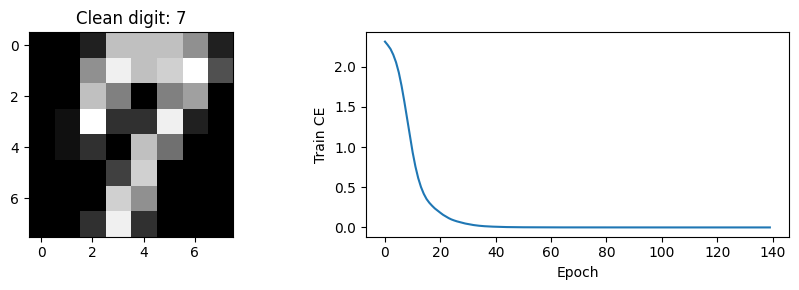

In [ ]:
digits = load_digits()
X = (digits.data / 16.0).astype(np.float32)
y = digits.target
ids = np.arange(len(y))
rest, test_ids = train_test_split(ids, test_size=500, random_state=42, stratify=y)
rest, pool_ids = train_test_split(rest, test_size=500, random_state=43, stratify=y[rest])
train_ids, val_ids = train_test_split(rest, train_size=600, random_state=44, stratify=y[rest])
groups = [train_ids, val_ids, pool_ids, test_ids]
assert len(set(np.concatenate(groups))) == len(X)
for i in range(4):
    for j in range(i):
        assert not set(groups[i]) & set(groups[j])
Xtr, ytr = X[train_ids], y[train_ids]
Xval, yval = X[val_ids], y[val_ids]
Xpool = X[pool_ids]
Xte, yte = X[test_ids], y[test_ids]
clean, clean_hist = fit(Xtr, ytr)
baseline_acc = acc(clean, Xte, yte)
results["baseline"] = {"train_accuracy": acc(clean, Xtr, ytr),
                       "validation_accuracy": acc(clean, Xval, yval),
                       "test_accuracy": baseline_acc}
display(pd.DataFrame([results["baseline"]]))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].imshow(Xtr[0].reshape(8, 8), cmap="gray", vmin=0, vmax=1)
ax[0].set_title(f"Clean digit: {ytr[0]}")
ax[1].plot(clean_hist); ax[1].set(xlabel="Epoch", ylabel="Train CE")
plt.tight_layout(); plt.show()

Модель хорошо запомнила train, но тест тоже высокий — это нормальный baseline.

### Задание A1. Label flipping

Реализуйте изменение ровно `floor(rate * n)` меток без изменения входов и без изменения исходного массива.
Новая метка должна отличаться от старой. Сравните доли 0, 0.1, 0.3 при одинаковой инициализации модели.
Это простой baseline отравления, а не оптимизированная атака.

In [ ]:
def flip_labels(y, rate, k, seed=42):
    rng = np.random.default_rng(seed)
    yf = y.copy()
    n = len(y)
    m = int(np.floor(rate * n))
    if m == 0:
        return yf, np.array([], dtype=int)
    changed = rng.choice(n, size=m, replace=False)
    # ненулевой сдвиг по модулю k гарантирует отличие от старой метки
    yf[changed] = (y[changed] + 1) % k
    return yf, changed

,poison_rate,n_changed,clean_test_accuracy
0,0.0,0,0.962
1,0.1,60,0.872
2,0.3,180,0.642


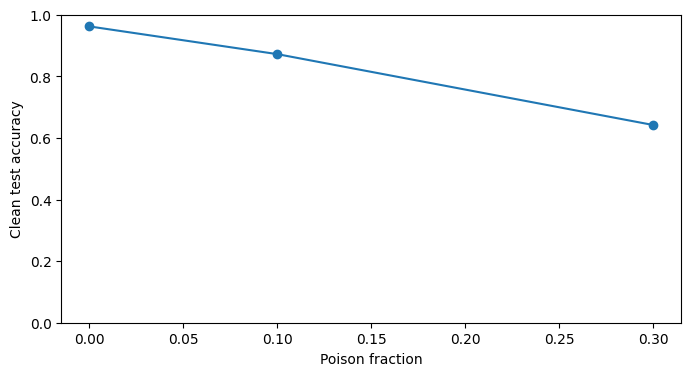

In [ ]:
flip_probe = flip_labels(ytr, 0.1, 10)
if flip_probe is None:
    pending("A1")
else:
    yf, changed = flip_probe
    assert len(changed) == 60 and np.sum(yf != ytr) == 60
    assert np.array_equal(ytr, y[train_ids])
    assert not np.shares_memory(yf, ytr)
    flip_rows = []
    for rate in [0, 0.1, 0.3]:
        yf, changed = flip_labels(ytr, rate, 10)
        m = clean if rate == 0 else fit(Xtr, yf)[0]
        flip_rows.append({"poison_rate": rate, "n_changed": len(changed),
                         "clean_test_accuracy": acc(m, Xte, yte)})
    results["label_flipping"] = flip_rows
    display(pd.DataFrame(flip_rows))
    plt.plot([r["poison_rate"] for r in flip_rows],
             [r["clean_test_accuracy"] for r in flip_rows], "o-")
    plt.xlabel("Poison fraction"); plt.ylabel("Clean test accuracy")
    plt.ylim(0, 1); plt.show()

На графике «Poison fraction» vs «Clean test accuracy» видно монотонное падение: 0.962 → 0.872 → 0.642. Это ожидаемо: случайное повреждение меток ухудшает обучение, особенно при 30%

Повреждение меток без изменения входов уже заметно снижает clean accuracy. Но это простой baseline, а не оптимизированная атака.

Модель угроз: атакующий имеет доступ к train-меткам и может их менять; входы не меняет.

## B. Backdoor: локальный dirty-label опыт

Атакующий заменяет часть train на изображения с патчем 2×2 в правом нижнем углу и меткой `target=0`.
При инференсе тот же патч должен направлять нетаргетные цифры в класс 0.
Это учебная реализация идеи [BadNets](https://arxiv.org/abs/1708.06733), не точное воспроизведение статьи.
Доля отравления определяется от ВСЕХ 600 train, а выбираются только записи с исходной меткой, отличной от 0.

$
ASR=\frac{\sum_{i:y_i\ne t}1[\arg\max f(T(x_i))=t]}{|\{i:y_i\ne t\}|}.
$

Проверяем четыре условия: clean model / poisoned model × clean input / triggered input.
ASR clean-модели на том же триггере показывает, не объясняется ли эффект одним повреждением входа.
Дополнительно считаем условный ASR на тех нетаргетных объектах, которые эта же модель правильно распознавала без патча.

### Задание B1. Триггер и отравление

`trigger` должен копировать вход, сохранять форму `(n,64)` и менять только последние 2×2 пикселя.
`poison_data` заменяет, а не добавляет записи; возвращает индексы изменений.
Для воспроизводимого сравнения выбор индексов должен зависеть только от `seed`.

In [ ]:
TARGET = 0
def trigger(x):
    # TODO: копия, reshape 8x8, патч 2x2, обратный reshape.
    z = x.copy().reshape(-1, 8, 8)
    z[:, -2:, -2:] = 1.0
    return z.reshape(-1, 64)
def poison_data(x, y, rate=0.15, target=TARGET, seed=42):
    # TODO: выбирайте только y != target, меняйте и изображение, и метку.
    rng = np.random.default_rng(seed)
    xp = x.copy()
    yp = y.copy()
    n = len(y)
    m = int(np.floor(rate * n))          # 0.15 * 600 = 90
    eligible = np.flatnonzero(y != target)  # не портим истинный target
    changed = rng.choice(eligible, size=m, replace=False)
    xp[changed] = trigger(x[changed])
    yp[changed] = target
    return xp, yp, changed

### Задание B2. Корректный знаменатель

Реализуйте ASR по уже вычисленным предсказаниям; возвращайте NaN, если допустимых объектов нет.
Не включайте истинный target-класс. Вызов не должен изменять массивы.

In [ ]:
def targeted_asr(pred, y, target):
    # TODO: маска y != target и доля pred == target внутри маски.
    pred = np.asarray(pred)
    y = np.asarray(y)
    mask = y != target
    if mask.sum() == 0:
        return float("nan")
    return float((pred[mask] == target).mean())

,model,clean_accuracy,ASR,ASR_n,conditional_ASR,conditional_n,triggered_accuracy
0,clean,0.962,0.0,450,0.0,433,0.742
1,poisoned,0.956,1.0,450,1.0,429,0.100


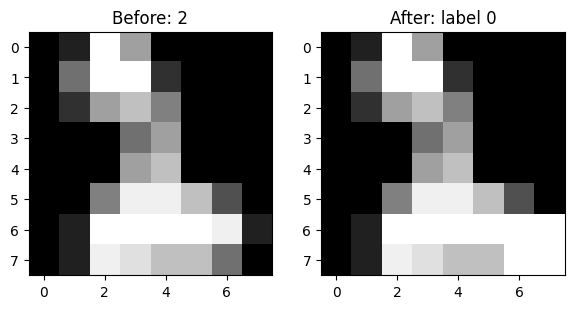

In [ ]:
poisoned = None
probe = poison_data(Xtr, ytr)
asr_probe = targeted_asr(np.array([0, 0, 1]), np.array([0, 2, 3]), 0)
if probe is None or asr_probe is None or trigger(Xtr[:1]) is None:
    pending("B1/B2")
else:
    assert asr_probe == 0.5
    assert np.isnan(targeted_asr(np.array([0]), np.array([0]), 0))
    xp, yp, ix = probe
    assert len(ix) == 90 and np.all(yp[ix] == TARGET) and np.all(ytr[ix] != TARGET)
    keep = np.setdiff1d(np.arange(len(ytr)), ix)
    assert np.array_equal(xp[keep], Xtr[keep])
    assert np.array_equal(Xtr, X[train_ids]) and np.array_equal(ytr, y[train_ids])
    assert not np.shares_memory(xp, Xtr)
    assert np.all(trigger(Xtr[:2]).reshape(-1, 8, 8)[:, -2:, -2:] == 1)
    mask_pixels = np.ones((8, 8), bool); mask_pixels[-2:, -2:] = False
    assert np.array_equal(trigger(Xtr[:2]).reshape(-1,8,8)[:,mask_pixels],
                          Xtr[:2].reshape(-1,8,8)[:,mask_pixels])
    poisoned, _ = fit(xp, yp)
    bd_rows = []
    for name, model in [("clean", clean), ("poisoned", poisoned)]:
        pc = probs(model, Xte).argmax(1)
        pt = probs(model, trigger(Xte)).argmax(1)
        eligible = (yte != TARGET) & (pc == yte)
        bd_rows.append({"model": name, "clean_accuracy": accuracy_score(yte, pc),
                        "ASR": targeted_asr(pt, yte, TARGET),
                        "ASR_n": int((yte != TARGET).sum()),
                        "conditional_ASR": float((pt[eligible] == TARGET).mean()),
                        "conditional_n": int(eligible.sum()),
                        "triggered_accuracy": accuracy_score(yte, pt)})
    results["backdoor"] = bd_rows
    display(pd.DataFrame(bd_rows))
    fig, ax = plt.subplots(1, 2, figsize=(6,3))
    ax[0].imshow(Xtr[ix[0]].reshape(8,8), cmap="gray", vmin=0, vmax=1)
    ax[0].set_title(f"Before: {ytr[ix[0]]}")
    ax[1].imshow(xp[ix[0]].reshape(8,8), cmap="gray", vmin=0, vmax=1)
    ax[1].set_title(f"After: label {yp[ix[0]]}")
    plt.tight_layout(); plt.show()

clean_accuracy у poisoned почти не упала: 0.956 против 0.962. Это ключевой момент: backdoor может быть скрытым.

ASR — доля нетаргетных test-примеров, которые после патча классифицируются в target=0. У poisoned = 1.0, у clean = 0.0.

ASR_n=450: из 500 test исключили истинный класс 0, осталось 450 «нетаргетных» примеров. Это правильно: примеры класса 0 не должны считаться успехом атаки.

conditional_ASR — ASR только на тех нетаргетных примерах, которые poisoned-модель и без патча классифицировала правильно. У poisoned = 1.0 на 429 примерах. Это показывает, что патч переводит в 0 даже корректно распознанные объекты.

triggered_accuracy у poisoned = 0.100: после патча почти всё уходит в 0, поэтому правильными остаются в основном истинные нули. У clean = 0.742: патч сам по себе ломает часть входов, но не направляет всё в target.

### Контроль защиты с известным триггером

Ниже защитник УЖЕ знает положение патча. Он зануляет эту область на ВСЕХ входах.
Это oracle-sanitization: полезный контроль причинности, но не детектор неизвестных backdoor.
Считаем и ASR, и потерю clean accuracy. Дополнительный опыт: fine-tuning на чистой validation;
после него эта выборка становится обучающей и больше не годится для независимой оценки.
Ни один из этих опытов не даёт универсальной гарантии ([NIST](https://nvlpubs.nist.gov/nistpubs/ai/NIST.AI.100-2e2025.pdf)).

,defense,clean_accuracy,ASR
0,No defense,0.956,1.000000
1,Known patch erase,0.956,0.002222
2,Clean fine-tuning,0.960,0.997778


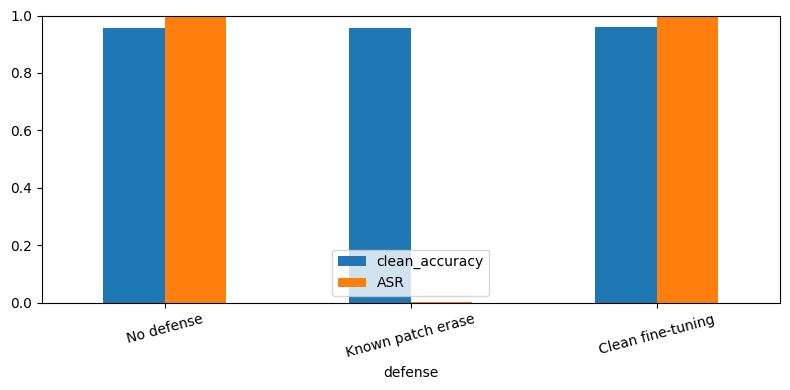

In [ ]:
def erase_known_patch(x):
    z = x.copy().reshape(-1,8,8)
    z[:, -2:, -2:] = 0
    return z.reshape(-1,64)

if poisoned is not None:
    ft = copy.deepcopy(poisoned)
    opt = torch.optim.Adam(ft.parameters(), lr=0.001)
    for _ in range(40):
        opt.zero_grad()
        loss = F.cross_entropy(ft(tensor(Xval)), torch.as_tensor(yval, dtype=torch.long))
        loss.backward(); opt.step()
    defense_rows = []
    for name, model, transform in [
        ("No defense", poisoned, lambda x: x),
        ("Known patch erase", poisoned, erase_known_patch),
        ("Clean fine-tuning", ft.eval(), lambda x: x)]:
        defense_rows.append({"defense": name, "clean_accuracy": acc(model, transform(Xte), yte),
                            "ASR": targeted_asr(probs(model, transform(trigger(Xte))).argmax(1), yte, TARGET)})
    results["backdoor_defense"] = defense_rows
    display(pd.DataFrame(defense_rows))
    pd.DataFrame(defense_rows).set_index("defense").plot.bar(rot=15, ylim=(0,1))
    plt.tight_layout(); plt.show()
else:
    pending("Backdoor defense")

Known patch erase зануляет известный патч на всех входах. ASR падает до 0.002, clean accuracy не страдает. Это oracle-защита: защитник уже знает положение патча.

Clean fine-tuning на чистой validation почти не убирает backdoor (Дообучение poisoned-модели на чистой validation. Validation после этого становится обучающей, независимая оценка теряется): ASR остаётся 0.998. Это важный отрицательный результат: дообучение на чистых данных не гарантирует удаление backdoor.

На bar-графике видно: clean_accuracy почти одинаковая у всех защит, а ASR резко падает только у Known patch erase. Clean fine-tuning выглядит «безопасным» по accuracy, но ASR почти 1.

Высокая clean accuracy не исключает высокий ASR. Backdoor-модель может быть почти такой же точной на чистых данных, но управляемой триггером.

## C. Membership inference: отдельный синтетический стенд

Определяем, входила ли запись `(x,y)` в train целевой модели.
Loss-score требует истинной метки и вектора вероятностей: это явно заданные возможности атакующего.
Используем отрицательную cross-entropy, то есть `log p(y|x)`; больший score означает «вероятнее member».
Идея shadow calibration связана с [Shokri et al.](https://arxiv.org/abs/1610.05820).

1600 синтетических записей делятся на 4 непересекающихся набора по 400:
target members, target nonmembers, shadow members, shadow nonmembers.
Shadow-данные и алгоритм обучения доступны атакующему. Порог выбирается ТОЛЬКО на shadow;
истинные membership-метки target открываются лишь оценщику после атаки.
Один shadow не является реализацией LiRA. Цель: честно показать принцип калибровки.

### Задание C1. Loss-score и порог

Напишите `membership_score` через логарифм вероятности истинного класса с защитой от log(0).
В `choose_threshold` максимизируйте balanced accuracy на calibration, перебрав уникальные score
и дополнительный порог выше максимума. Используйте соглашение `score >= threshold`.

Membership inference (MIA) — атака: по ответам модели угадать, входила ли конкретная запись в её обучающую выборку.

Нужно выбрать порог: если score > порог, говорим «member», иначе «nonmember» - используем shadow-модель. Это модель-дублёр, обученная на других данных, где атакующий знает ответы. По ней подбираем порог — как будто «репетируем» атаку.

Учим target-модель (жертву) на target members.

Учим shadow-модель на shadow members.

На shadow-модели смотрим score для shadow members и shadow nonmembers → выбираем порог.

На target-модели считаем score для target members и nonmembers → применяем порог → проверяем, насколько хорошо угадали.

In [ ]:
def membership_score(p, labels):
    # TODO: выберите p истинной метки, clip, log.
    p = np.asarray(p, dtype=np.float64)
    labels = np.asarray(labels)
    eps = 1e-12
    chosen = p[np.arange(len(labels)), labels]
    return np.log(np.clip(chosen, eps, 1.0))

def choose_threshold(scores, member):
    # TODO: выбирайте порог только по переданным calibration-данным.
    scores = np.asarray(scores)
    member = np.asarray(member)
    candidates = np.unique(scores)
    candidates = np.append(candidates, candidates.max() + 1.0)
    best_thr, best_ba = candidates[0], -1.0
    for thr in candidates:
        pred = (scores >= thr).astype(int)
        ba = balanced_accuracy_score(member, pred)
        if ba > best_ba:
            best_ba, best_thr = ba, thr
    return best_thr

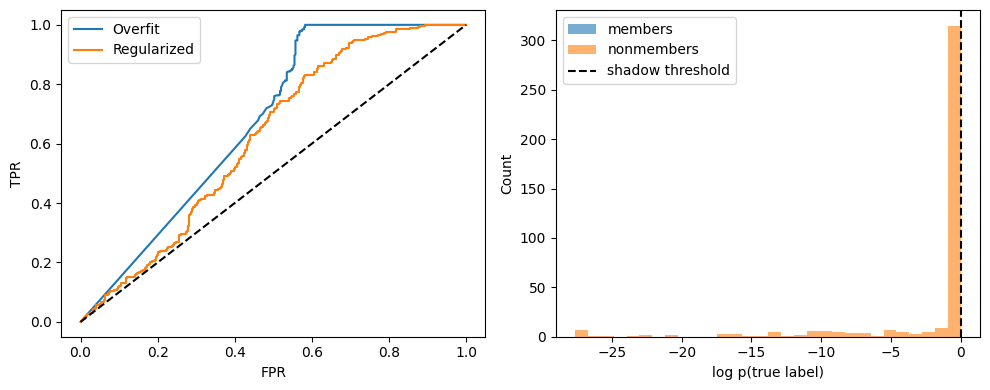

,setting,train_accuracy,nonmember_accuracy,gap,threshold_shadow,ROC_AUC,balanced_accuracy,TPR,FPR,advantage,TPR_at_empirical_FPR_le_1pct
0,Overfit,1.0000,0.7825,0.2175,-0.000037,0.671647,0.7075,1.00,0.585,0.415,0.00
1,Regularized,0.9825,0.8175,0.1650,-0.337439,0.618344,0.6200,0.94,0.700,0.240,0.01


Минимальный ненулевой шаг FPR = 0.0025 ; 1% соответствует всего 4 FP, оценка нестабильна.


In [ ]:
mia_probe = membership_score(np.array([[.9,.1],[.2,.8]]), np.array([0,1]))
if mia_probe is None or choose_threshold(np.array([-2., -1.]), np.array([0,1])) is None:
    pending("C1")
else:
    np.testing.assert_allclose(mia_probe, np.log([.9,.8]))
    threshold_probe = choose_threshold(np.array([-3.,-2.,-1.,-.1]), np.array([0,0,1,1]))
    assert balanced_accuracy_score([0,0,1,1], np.array([-3.,-2.,-1.,-.1]) >= threshold_probe) == 1
    XM, yM = make_classification(n_samples=1600, n_features=40, n_informative=12,
                                 n_redundant=8, class_sep=0.7, flip_y=0.08, random_state=51)
    mi = np.arange(1600)
    a, b = train_test_split(mi, test_size=800, random_state=52, stratify=yM)
    tm, tn = train_test_split(a, test_size=400, random_state=53, stratify=yM[a])
    sm, sn = train_test_split(b, test_size=400, random_state=54, stratify=yM[b])
    assert len(set(np.r_[tm,tn,sm,sn])) == 1600
    # Фиксированное масштабирование, а не fit scaler по test.
    XM = (XM / 5.0).astype(np.float32)
    member = np.r_[np.ones(400, int), np.zeros(400, int)]
    evaluation_ids, calibration_ids = np.r_[tm,tn], np.r_[sm,sn]
    mia_rows = []
    fig, axes = plt.subplots(1,2, figsize=(10,4))
    for name, epochs, wd in [("Overfit", 400, 0.0), ("Regularized", 60, 0.02)]:
        victim, _ = fit(XM[tm], yM[tm], k=2, epochs=epochs, wd=wd, width=96, seed=61)
        shadow, _ = fit(XM[sm], yM[sm], k=2, epochs=epochs, wd=wd, width=96, seed=62)
        cal_s = membership_score(probs(shadow, XM[calibration_ids]), yM[calibration_ids])
        threshold = choose_threshold(cal_s, member)
        s = membership_score(probs(victim, XM[evaluation_ids]), yM[evaluation_ids])
        guessed = s >= threshold
        tpr = float(guessed[:400].mean()); fpr = float(guessed[400:].mean())
        roc_fpr, roc_tpr, _ = roc_curve(member, s)
        low = float(roc_tpr[roc_fpr <= .01].max())
        train_acc, test_acc = acc(victim, XM[tm], yM[tm]), acc(victim, XM[tn], yM[tn])
        mia_rows.append({"setting": name, "train_accuracy": train_acc, "nonmember_accuracy": test_acc,
                         "gap": train_acc-test_acc, "threshold_shadow": threshold,
                         "ROC_AUC": roc_auc_score(member,s),
                         "balanced_accuracy": balanced_accuracy_score(member,guessed),
                         "TPR": tpr, "FPR": fpr, "advantage": tpr-fpr,
                         "TPR_at_empirical_FPR_le_1pct": low})
        axes[0].plot(roc_fpr, roc_tpr, label=name)
        if name == "Overfit":
            axes[1].hist(s[:400], bins=30, alpha=.6, label="members")
            axes[1].hist(s[400:], bins=30, alpha=.6, label="nonmembers")
            axes[1].axvline(threshold, color="black", linestyle="--", label="shadow threshold")
    axes[0].plot([0,1],[0,1],"k--")
    axes[0].set(xlabel="FPR", ylabel="TPR"); axes[0].legend()
    axes[1].set(xlabel="log p(true label)", ylabel="Count"); axes[1].legend()
    plt.tight_layout(); plt.show()
    results["membership"] = mia_rows
    display(pd.DataFrame(mia_rows))
    print("Минимальный ненулевой шаг FPR =", 1/400,
          "; 1% соответствует всего 4 FP, оценка нестабильна.")

Overfit — 400 эпох, без регуляризации. Запоминает train наизусть (train accuracy = 1.0). Разница между train и test большая → легче атаковать.

Regularized — 60 эпох, с регуляризацией. Не запоминает так сильно (train accuracy = 0.9825). Разница меньше → сложнее атаковать.

Пунктир - гадание 50/50, видно, что атаки успешнее, но с регулязацией атака хуже.

ROC_AUC — качество ранжирования
Площадь под ROC-кривой. Диапазон [0, 1].

0.5 — атака не лучше монетки.

1.0 — идеально разделяет members и nonmembers.

Overfit = 0.672 → сигнал есть, но слабый.

Regularized = 0.618 → сигнал слабее.
случайно взятый member имеет score выше случайно взятого nonmember в 67% (или 62%) случаев

advantage = TPR − FPR
Насколько атака лучше случайного угадывания при выбранном пороге.

При малом FPR	Оценки (0.00 / 0.01) ненадёжны — всего 4 FP из 400.


### Интерпретация C

ROC-AUC оценивает ранжирование, а balanced accuracy, TPR и FPR выше относятся к порогу,
заранее выбранному на shadow. `TPR_at_empirical_FPR_le_1pct` является описательной точкой
ROC по итоговому test, НЕ рабочим порогом, который разрешено подобрать по test.
Не выдавайте эту оценку за гарантию при FPR 0.1%: 400 nonmembers недостаточно для надёжного анализа хвоста.
Важность low-FPR оценки обсуждается в [Carlini et al.](https://arxiv.org/abs/2112.03570).

При доле участников $\pi$ среди проверяемых записей:
$
PPV=\frac{TPR\pi}{TPR\pi+FPR(1-\pi)}.
$

При TPR=0.6, FPR=0.1 и $\pi=0.01$ точность положительного заключения составляет около 5.7%.
Сбалансированный стенд сам по себе этого не показывает.
Снижение риска при регуляризации является эмпирическим результатом, не differential privacy.

In [ ]:
pi, tpr_example, fpr_example = .01, .6, .1
ppv = tpr_example*pi / (tpr_example*pi + fpr_example*(1-pi))
assert np.isclose(ppv, .05714285714285714)
print(f"Пример PPV = {ppv:.2%}")

Пример PPV = 5.71%


PPV = какая доля из тех, кого атака назвала member'ами, действительно member'ы.

 π = доля member'ов среди проверяемых.

 из 100 только 5-6 являют, Атака почти бесполезна на практике.

## D. Model inversion: оптимизация входа

Доступ white-box: атакующий знает веса и получает градиент по входу, но НЕ использует train в оптимизации.
Синтезируем изображение класса $c$, минимизируя
$
L(x)=-\log p_\theta(c\mid x)+0.02\|x\|_2^2/d+0.05\,TV(x),\quad x\in[0,1]^{64}.
$

Здесь TV равна сумме средних абсолютных разностей по двум направлениям.
Это демонстрация class-prototype inversion. Она НЕ доказывает извлечение конкретной обучающей записи;
близость к train оценивается отдельно только преподавателем-аудитором.
Связь confidence и inversion изучается в [Fredrikson et al.](https://www.cs.cmu.edu/~mfredrik/papers/fjr2015ccs.pdf).

### Задание D1. Функция потерь и градиент по входу
Верните скалярную функцию потерь для батча восстанавливаемых изображений.
Нельзя использовать `.detach()` или NumPy внутри loss: градиент должен доходить до `x`.
Оптимизатор ниже меняет только `x`, веса модели фиксированы.

In [ ]:
def inversion_loss(model, x, classes):
    # TODO: cross_entropy + средний L2 + TV по двум пространственным осям.
    logits = model(x)
    ce = F.cross_entropy(logits, classes)
    d = x.shape[1]
    l2 = (x * x).sum(dim=1).mean() / d
    z = x.reshape(-1, 8, 8)
    tv_row = (z[:, 1:, :] - z[:, :-1, :]).abs().mean(dim=(1, 2))
    tv_col = (z[:, :, 1:] - z[:, :, :-1]).abs().mean(dim=(1, 2))
    tv = (tv_row + tv_col).mean()
    return ce + 0.02 * l2 + 0.05 * tv

,class,restart,confidence,nearest_train_MSE,nearest_test_MSE,nref_each
0,0,0,0.999849,0.114259,0.116033,50
1,0,1,1.000000,0.149207,0.152763,50
2,3,0,1.000000,0.152829,0.146404,51
3,3,1,0.999999,0.145224,0.133860,51
4,8,0,0.999904,0.163195,0.162981,48
5,8,1,0.999855,0.157693,0.167334,48


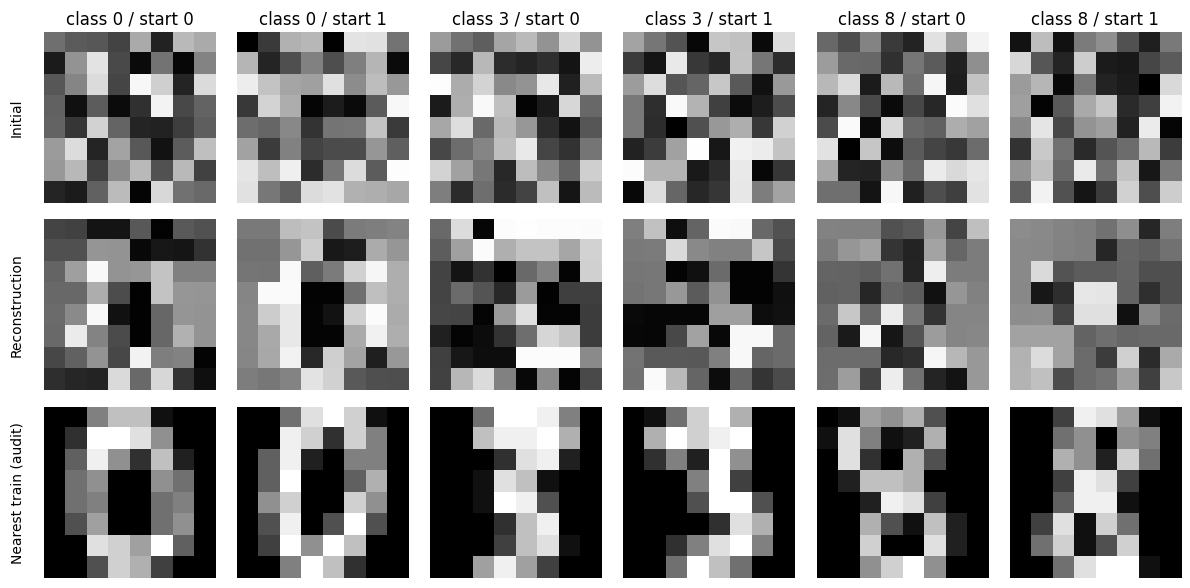

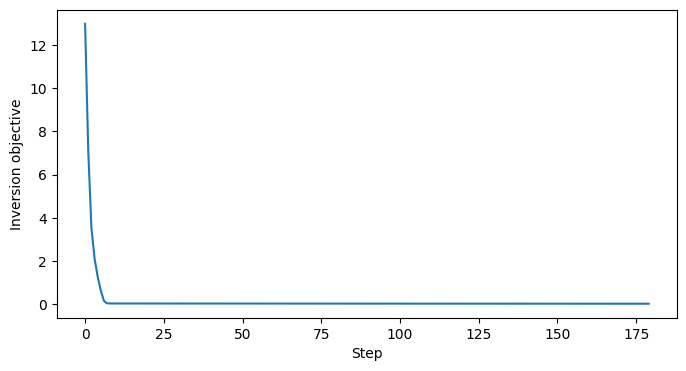

In [ ]:
inverse_probe_x = torch.full((2,64), .5, requires_grad=True)
inverse_probe = inversion_loss(clean, inverse_probe_x, torch.tensor([0,1]))
if inverse_probe is None:
    pending("D1")
else:
    assert inverse_probe.ndim == 0
    grad = torch.autograd.grad(inverse_probe, inverse_probe_x)[0]
    assert torch.isfinite(grad).all() and grad.abs().sum() > 0
    before_weights = [p.detach().clone() for p in clean.parameters()]
    for p in clean.parameters():
        p.requires_grad_(False)
    # Два старта для каждого из трёх классов.
    classes = torch.tensor([0,0,3,3,8,8], dtype=torch.long)
    torch.manual_seed(70)
    inv_x = torch.rand((6,64), requires_grad=True)
    initial = inv_x.detach().numpy().copy()
    opt_x = torch.optim.Adam([inv_x], lr=.04)
    inv_hist = []
    for _ in range(180):
        opt_x.zero_grad()
        loss = inversion_loss(clean, inv_x, classes)
        loss.backward(); opt_x.step()
        with torch.no_grad():
            inv_x.clamp_(0,1)
        inv_hist.append(loss.item())
    recon = inv_x.detach().numpy()
    assert all(torch.equal(p, old) for p,old in zip(clean.parameters(), before_weights))
    for p in clean.parameters():
        p.requires_grad_(True)
    # Аудиторский доступ: ближайшие train и held-out не входят в атакующую оптимизацию.
    rows, nearest_train = [], []
    for i, cls in enumerate(classes.numpy()):
        tri = np.flatnonzero(ytr == cls); tei = np.flatnonzero(yte == cls)
        # Одинаковое число кандидатов, чтобы размер множества не смещал nearest-neighbor baseline.
        nref = min(len(tri), len(tei)); tri, tei = tri[:nref], tei[:nref]
        dtr = ((Xtr[tri]-recon[i])**2).mean(1)
        dte = ((Xte[tei]-recon[i])**2).mean(1)
        nearest_train.append(Xtr[tri[dtr.argmin()]])
        rows.append({"class": int(cls), "restart": i%2,
                     "confidence": float(probs(clean,recon[i:i+1])[0,cls]),
                     "nearest_train_MSE": float(dtr.min()),
                     "nearest_test_MSE": float(dte.min()), "nref_each": nref})
    results["inversion"] = rows
    display(pd.DataFrame(rows))
    fig, ax = plt.subplots(3,6, figsize=(12,6))
    for i in range(6):
        for r, arr in enumerate([initial, recon, np.array(nearest_train)]):
            ax[r,i].imshow(arr[i].reshape(8,8), cmap="gray", vmin=0, vmax=1)
            ax[r,i].axis("off")
        ax[0,i].set_title(f"class {classes[i].item()} / start {i%2}")
    for r,label in enumerate(["Initial", "Reconstruction", "Nearest train (audit)"]):
        ax[r,0].text(-.2,.5,label, transform=ax[r,0].transAxes, rotation=90, va="center")
    plt.tight_layout(); plt.show()
    plt.plot(inv_hist); plt.xlabel("Step"); plt.ylabel("Inversion objective"); plt.show()

У нас есть обученная модель. Мы не имеем доступа к train. Но мы знаем веса модели (white-box) — можем считать градиент.

Мы оптимизируем картинку x так, чтобы модель была максимально уверена, что это класс c

MSE — средний квадрат разницы между пикселями. Чем меньше, тем ближе. Мы для каждой восстановленной картинки нашли самую похожую настоящую цифру того же класса

Initial — начальный случайный шум.

Reconstruction — что оптимизация нарисовала. Видно что-то похожее на цифру (0, 3, 8), но размытое, обобщённое.

Nearest train (audit) — самый похожий настоящий train-пример того же класса.

оптимизация быстро сходится. Модель легко «обманывается» картинкой, которая выглядит как цифра.

Model inversion восстанавливает обобщённый образ класса, а не конкретную обучающую запись.

## E. Model extraction: локальный API с бюджетом

Цель: скопировать предсказания, а не восстановить точные веса.
Атакующий видит только свои query-входы и ответ API; метки `ytr`, `yte`, `y[pool_ids]` не используются в fit клона.
Ниже сравниваются soft probabilities и hard labels при равных бюджетах уникальных примеров.
Идея prediction-API extraction: [Tramèr et al.](https://arxiv.org/abs/1609.02943).
API является программной границей эксперимента, не защищённым процессом: владелец блокнота технически видит все переменные.

Чтобы не платить за одни и те же запросы повторно, один раз получаем 500 ответов и кэшируем их.
Модели с бюджетом 50/150/500 получают только соответствующий префикс ответов.
В эксплуатации метрики аудита потребовали бы отдельного доступа оценщика;
здесь он считает fidelity на test напрямую и не расходует бюджет атакующего.

Model extraction — это когда строим свою модель (клон), которая отвечает так же, как оригинал. Платим за запросы (не за веса).

### Задание E1. Дистилляция

Реализуйте soft cross-entropy по logits student и распределению teacher.
Не передавайте вероятности как logits в `cross_entropy`.
Для hard-label варианта используется стандартная cross-entropy с argmax teacher.

In [ ]:
def distill_loss(logits, teacher_p):
    # TODO: log_softmax по классу, сумма по классу и среднее по батчу.
    log_softmax = F.log_softmax(logits, dim=1)
    return -(teacher_p * log_softmax).sum(dim=1).mean()

,queries_available,output,fidelity,clone_accuracy,victim_accuracy
0,50,soft,0.772,0.760,0.962
1,50,hard,0.734,0.730,0.962
2,150,soft,0.930,0.912,0.962
3,150,hard,0.894,0.880,0.962
4,500,soft,0.960,0.950,0.962
5,500,hard,0.950,0.938,0.962


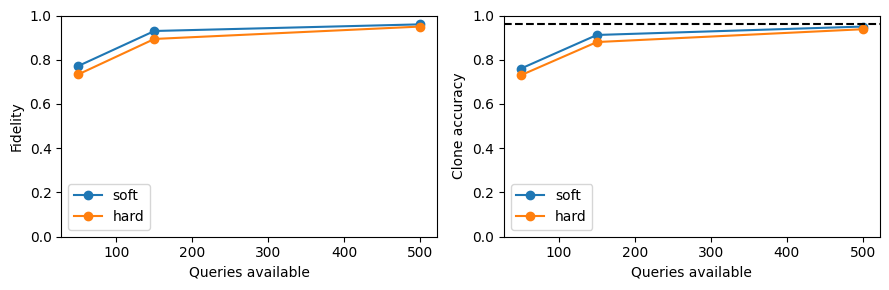

Всего запросов к API в этом опыте: 500


In [ ]:
class LocalAPI:
    def __init__(self, model, budget=500):
        self.__model = model
        self.budget, self.used = budget, 0
    def query(self, x):
        if self.used + len(x) > self.budget:
            raise RuntimeError("Query budget exceeded")
        self.used += len(x)
        return probs(self.__model, x)

dl_probe = distill_loss(torch.zeros(2,10, requires_grad=True), torch.full((2,10), .1))
if dl_probe is None:
    pending("E1")
else:
    assert torch.isclose(dl_probe.detach(), torch.tensor(np.log(10), dtype=torch.float32))
    api = LocalAPI(clean, budget=500)
    order = np.random.default_rng(80).permutation(len(Xpool))
    queries = Xpool[order]
    cached_answers = api.query(queries)
    assert api.used == 500
    try:
        api.query(queries[:1])
        raise AssertionError("Budget is not enforced")
    except RuntimeError:
        pass
    victim_test_labels = probs(clean, Xte).argmax(1)
    extraction_rows = []
    for budget in [50,150,500]:
        for mode in ["soft", "hard"]:
            # Это все обучающие данные, доступные данной модели-клону.
            qx, qp = tensor(queries[:budget]), tensor(cached_answers[:budget])
            student = new_model(64,10,seed=81,width=32)
            optimizer = torch.optim.Adam(student.parameters(), lr=.01, weight_decay=1e-4)
            for _ in range(160):
                optimizer.zero_grad()
                logits = student(qx)
                loss = distill_loss(logits, qp) if mode == "soft" else F.cross_entropy(logits, qp.argmax(1))
                loss.backward(); optimizer.step()
            clone_pred = probs(student.eval(), Xte).argmax(1)
            extraction_rows.append({"queries_available": budget, "output": mode,
                                    "fidelity": accuracy_score(victim_test_labels, clone_pred),
                                    "clone_accuracy": accuracy_score(yte, clone_pred),
                                    "victim_accuracy": baseline_acc})
    results["extraction"] = extraction_rows
    display(pd.DataFrame(extraction_rows))
    fig, ax = plt.subplots(1,2, figsize=(9,3))
    ef = pd.DataFrame(extraction_rows)
    for mode in ["soft","hard"]:
        sub = ef[ef.output == mode]
        ax[0].plot(sub.queries_available, sub.fidelity, "o-", label=mode)
        ax[1].plot(sub.queries_available, sub.clone_accuracy, "o-", label=mode)
    for a in ax:
        a.set(xlabel="Queries available", ylim=(0,1)); a.legend()
    ax[0].set_ylabel("Fidelity"); ax[1].set_ylabel("Clone accuracy")
    ax[1].axhline(baseline_acc, color="black", linestyle="--")
    plt.tight_layout(); plt.show()
    print("Всего запросов к API в этом опыте:", api.used)

50 запросов: fidelity ~0.75 — клон воспроизводит жертву только в 75% случаев. Слабо.

150: fidelity ~0.90 — уже близко.

500: fidelity ~0.96 — почти неотличим от жертвы на тестах. Клон готов.

На всех бюджетах soft чуть выше hard (на 2–4%).

Почему: soft несёт больше информации (не только «что правильный ответ», но и «насколько уверен», «какие альтернативы»). Учиться по вероятностям легче.

Но hard тоже работает — просто нужно больше запросов для того же качества.

Вывод: клон может точно копировать поведение, но не быть хорошей моделью/ Fidelity = «совпадает ли клон с жертвой на тех же входах». Смотрим только на argmax и сравниваем с argmax жертвы.

В нашем опыте жертва сильная (0.962), поэтому fidelity и accuracy близки.

## F. Протокол и отчёт

### Задание F1. Анализ и расширение

В основной части сформулируйте по одному выводу для A–E и один отрицательный/неоднозначный результат.
Для каждого укажите модель угроз, доступ атакующего, контроль, числитель и знаменатель метрики,
а также то, что из результата НЕ следует.

Выберите один вариант:

- **Backdoor**: сравните доли 0.05, 0.15, 0.25 на трёх seed; оставьте фиксированными патч и target.
- **Membership**: повторите оба режима на трёх seed; сравните AUC и PPV при pi=0.01/0.1/0.5.
- **Inversion**: сравните TV=0 и TV=0.05 на трёх seed; сопоставьте confidence и видимость класса.
- **Extraction**: повторите кривые бюджетов на трёх seed; сравните разброс soft/hard fidelity.

Выбор варианта согласуется до просмотра итогового test. При изменении гиперпараметров используйте
validation или отдельный development-стенд. Не используйте обучающую метку public pool для клона.
Покажите mean ± sample SD; не называйте интервал mean ± SD доверительным.
Не исключайте «неудачные» seed.

### Вопросы

- **Целостность данных**: чем случайная ошибка разметки отличается от намеренного poisoning?
случайная ошибка делает модель хуже, poisoning — делает модель специфически управляемой, оставаясь незаметной на чистых тестах
- **Backdoor**: почему высокая clean accuracy не исключает высокий ASR? Зачем исключать target из знаменателя?
clean accuracy и ASR — на разных распределениях входов; высокая точность на одном не означает низкий ASR на другом. Target-класс исключается из знаменателя: триггер не должен менять уже правильные предсказания target.
- **MIA**: зачем нужен shadow? Почему порог на target test означает утечку методики оценки?
Shadow-модель имитирует обучение victim и даёт распределение score для members/nonmembers без доступа к target-меткам membership. По нему выбирают порог. Если выбирать порог по target test с истинными membership-метками, то оценщик использует информацию, которой у реального атакующего нет. Это evaluation leakage: метрики становятся оптимистичными и не воспроизводят реальную атаку.
- **Приватность**: почему AUC=0.5 у одной атаки не доказывает отсутствие утечек?
AUC=0.5 означает, что конкретный score/атака не ранжирует members лучше random. Но могут быть другие атаки, другие выходы модели, другие auxiliary-данные, другие подгруппы, low-FPR режимы, attribute inference или утечки через обновления. Отсутствие сигнала в одной атаке — не доказательство отсутствия утечек. Это «absence of evidence», а не «evidence of absence».
- **Inversion**: почему высокая confidence и похожая картинка не доказывают кражу конкретной записи?
Высокая confidence означает лишь, что модель уверенно относит синтезированный вход к классу. Восстановление может быть типичным прототипом класса, общим для многих объектов. В таблице nearest_train_MSE не меньше nearest_test_MSE, то есть нет доказательства, что восстановлена именно train-запись. Нужен отдельный membership/nearest-neighbor аудит; визуальная похожесть субъективна.
- **Extraction**: почему модель-клон может иметь высокую fidelity, но низкую accuracy?
Fidelity сравнивает клон с victim, а accuracy — с истинными метками. Если victim ошибается, клон может faithfully копировать эти ошибки: согласие с victim высокое, а правильность по ground truth ниже. Fidelity измеряет поведенческое копирование, accuracy — качество решения задачи. Также fidelity может быть высокой на test, даже если клон не восстановил веса.
- **Защита**: почему weight decay и ограничение API не дают гарантии differential privacy?
Weight decay — эвристическая регуляризация; она может снизить overfitting и membership-сигнал, но не даёт формальной границы влияния одной записи на выход. Ограничение API уменьшает бюджет запросов, но не делает выходы модели DP; повторные запросы, auxiliary-данные, разные аккаунты и side channels могут обойти ограничение. DP требует формального механизма: clipping, шум, бюджет ε, анализ соседних датасетов. Ни weight decay, ни query limit этого не обеспечивают.
### Что сдавать

Сдайте заполненный `.ipynb` с выводами и графиками, таблицу результатов, версии среды,
seed и краткое заключение (до 2 страниц). Все TODO должны быть реализованы.
Если блок пропущен, строка «не выполнено» не является результатом эксперимента.
Отсутствие ошибок при Run All само по себе не означает выполнения лабораторной.

,poison_rate,n_changed,CA_mean,CA_sd,ASR_mean,ASR_sd,cASR_mean,cASR_sd,cASR_n
0,0.05,30,0.962667,0.003055,0.976296,0.022259,0.975397,0.023132,431
1,0.15,90,0.961333,0.009238,0.991852,0.010502,0.991481,0.011031,429
2,0.25,150,0.962000,0.005292,1.000000,0.000000,1.000000,0.000000,431


,seed,poison_rate,n_changed,CA,ASR,conditional_ASR,conditional_n
0,42,0.05,30,0.960,0.997778,0.997680,431
1,42,0.15,90,0.956,1.000000,1.000000,429
2,42,0.25,150,0.960,1.000000,1.000000,431
3,43,0.05,30,0.962,0.953333,0.951501,433
4,43,0.15,90,0.956,0.980000,0.979021,429
5,43,0.25,150,0.958,1.000000,1.000000,430
6,44,0.05,30,0.966,0.977778,0.977011,435
7,44,0.15,90,0.972,0.995556,0.995423,437
8,44,0.25,150,0.968,1.000000,1.000000,435


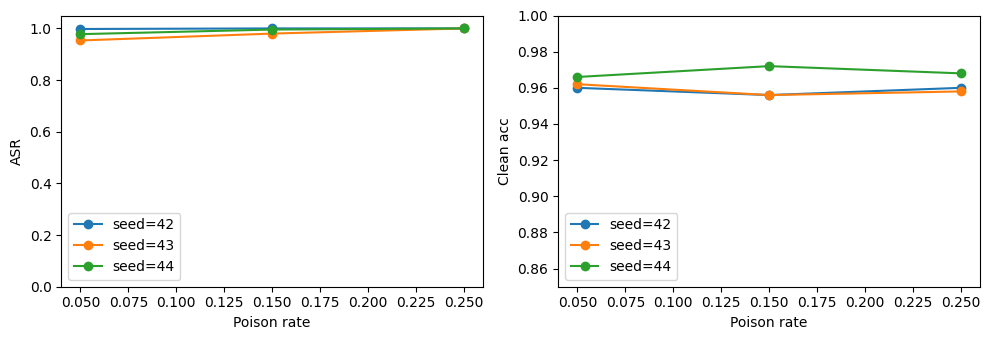

In [ ]:
POISON_RATES = [0.05, 0.15, 0.25]
SEEDS = [42, 43, 44]                # не исключаем «неудачные» — все три идут в отчёт
ext_rows = []

for seed in SEEDS:
    for rate in POISON_RATES:
        xp, yp, ix = poison_data(Xtr, ytr, rate=rate, target=TARGET, seed=seed)
        model, _ = fit(xp, yp, seed=seed)               # seed → и выбор индексов, и init
        pc = probs(model, Xte).argmax(1)
        pt = probs(model, trigger(Xte)).argmax(1)
        eligible = (yte != TARGET) & (pc == yte)        # для conditional ASR
        ext_rows.append({
            "seed": seed,
            "poison_rate": rate,
            "n_changed": int(len(ix)),
            "CA":  accuracy_score(yte, pc),
            "ASR": targeted_asr(pt, yte, TARGET),
            "conditional_ASR": float((pt[eligible] == TARGET).mean())
                               if eligible.sum() else float("nan"),
            "conditional_n": int(eligible.sum()),
        })

ext_df = pd.DataFrame(ext_rows)

# mean ± sample SD по трём seed для каждой доли
summary = (ext_df.groupby("poison_rate")
           .agg(n_changed=("n_changed", "first"),
                CA_mean=("CA", "mean"),       CA_sd=("CA", "std"),
                ASR_mean=("ASR", "mean"),     ASR_sd=("ASR", "std"),
                cASR_mean=("conditional_ASR", "mean"),
                cASR_sd=("conditional_ASR", "std"),
                cASR_n=("conditional_n", "first"))
           .reset_index())
display(summary)
display(ext_df)                                       # «сырые» три seed

# Разброс ASR по seed в рабочей точке
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for seed, sub in ext_df.groupby("seed"):
    ax[0].plot(sub.poison_rate, sub.ASR, "o-", label=f"seed={seed}")
    ax[1].plot(sub.poison_rate, sub.CA,  "o-", label=f"seed={seed}")
ax[0].set(xlabel="Poison rate", ylabel="ASR",     ylim=(0, 1.05)); ax[0].legend()
ax[1].set(xlabel="Poison rate", ylabel="Clean acc", ylim=(0.85, 1.0)); ax[1].legend()
plt.tight_layout(); plt.show()

results["backdoor_rates"] = ext_rows

Даже 5% отравления хватает для ASR ~97.6% при сохранении точности ~96.3%. При 25% — 100% ASR при нулевом разбросе. Backdoor эффективен и стабилен, а чистая точность ничего не подозревает.

Слева — ASR vs poison rate:

Три линии (seed 42, 43, 44).

Начинаются с ~0.95–1.0 при 5%.

Сходятся к 1.0 при 25%.

Справа — Clean acc vs poison rate:

Три линии почти горизонтальны, около 0.96.

Ни одна доля отравления не роняет точность заметно.